# Spectroscopy 2 — detect peaks **after** percentile-baseline removal

Omg omg ok so i just realised that doing the band thing works even better after percentile correcting to get peaks

And the percentile corrected peaks are beautiful

Lets goooo

I am going to copy and paste my old functions as much as possible, so forgive the strange ordering; see spectrscopy_reasoned for the original context (there will be weird comments)

**Settings:** Edit `BASELINE_PERCENTILE` and `BASELINE_WINDOW` in the imports cell.
All main pipeline and diagnostic calls inherit them. The parameter sweep
intentionally tests other values without changing the main settings.
Reference matching now tolerates small peak-position shifts (inspect assignments).


In [499]:
# imports
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

import cv2

import tifffile

from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.signal import peak_widths

from pathlib import Path

from PIL import Image

import pandas as pd

from scipy.interpolate import PchipInterpolator

from scipy.ndimage import percentile_filter

from matplotlib.patches import Rectangle

import matplotlib.patheffects as pe
# ============================================================
# MAIN PIPELINE SETTINGS -- CHANGE THESE TWO VALUES ONLY
# ============================================================
BASELINE_PERCENTILE = 25
BASELINE_WINDOW = 70  # samples in half-resolution Bayer profile (~122 RAW pixels)


In [500]:
# we've lost a lot of the faint bands from summing background
# let's fix this by only summing the relavant bands
# also the compression ot preview is doing nasty stuff (WHY is that default????)
# make func to get proper pics and get bands

def get_full_pic(pic):
    with tifffile.TiffFile(pic) as tif:
        img = tif.series[1].asarray()
    return img

def get_band(pic, band_prop = 5): # where band occupies 1/band_prop of vert area
    #print(f"Image: {pic}")
    img = get_full_pic(pic)
    h, w = img.shape
    #print(img.shape) #(3040, 4056)

    # get brightest 1/5 of image rows next to each other
    row_total_brightness = np.sum(img, axis = 1)
    #print(len(row_total_brightness)) 3040, correct

    cumulative = np.concatenate((
        [0],
        np.cumsum(row_total_brightness)
    ))

    band_size = h // band_prop
    window_sums = (
        cumulative[band_size:] -
        cumulative[:-band_size]
    )

    y_0 = int(np.argmax(window_sums))

    return y_0, y_0 + band_size

In [501]:
def vert_sum(pic, banded = True):
    img = get_full_pic(pic)

    if banded == True:
        start, end = get_band(pic)
    else:
        start, end = 0, len(img)

    img_bands = img[start:end]
    h, w = img_bands.shape
    #print(img_bands)
    #print(vert_sum)
    # print(np.sum((img), axis = 0))
    # print(len(np.sum((img), axis = 0)))
    return np.sum(img_bands, axis=0, dtype=np.float64)



In [502]:
# that is wonderful
# grab wavelength from each spot

# first step: get rgb from each spot

# but to do that we need to deal with bayer blocks

# the bayer pattern is NOT fun to work with
# [b, g, b, g]
# [g, r, g, r]
# [b, g, b, g]
# [g, r, g, r]
# b: both even
# g: one odd one even
# r: both odd

def get_bayer_profiles(pic):
    '''bayer profiles across pic, by horizontal section 
    (only vertical averaging, no horixontal)'''
    img = get_full_pic(pic)
    y0, y1 = get_band(pic)

    # align to complete BGGR Bayer blocks
    y0 = max(0, 2 * (y0 // 2))
    y1 = min(img.shape[0], 2 * (y1 // 2))

    region = img[y0:y1]

    # BGGR:
    # B G
    # G R

    B = region[0::2, 0::2].mean(axis=0)
    G1 = region[0::2, 1::2].mean(axis=0)
    G2 = region[1::2, 0::2].mean(axis=0)
    R = region[1::2, 1::2].mean(axis=0)

    G = (G1 + G2) / 2

    # each Bayer block corresponds to 2 sensor columns
    x = np.arange(len(R)) * 2 + 0.5

    return x, np.column_stack([R, G, B])

In [503]:
# redoing background correction
def get_percentile_baseline(pic, percentile=None, window=None):
    percentile = BASELINE_PERCENTILE if percentile is None else percentile
    window = BASELINE_WINDOW if window is None else window
    x, profiles = get_bayer_profiles(pic)

    baseline = np.column_stack([
        percentile_filter(
            profiles[:, i],
            percentile=percentile,
            size=window,
            mode="nearest"
        )
        for i in range(3)
    ])

    return x, profiles, baseline



In [504]:
# The only substantive pipeline change: find peaks AFTER baseline subtraction.
def corrected_peak_profile(pic, percentile=None, window=None):
    x, profiles, baseline = get_percentile_baseline(pic, percentile, window)
    corrected = profiles - baseline
    intensity = corrected.sum(axis=1)
    # Interpolate from 2-pixel Bayer-block positions to original pixel coordinates.
    # This keeps existing peak IDs, plot overlays and extraction windows compatible.
    full_x = np.arange(get_full_pic(pic).shape[1])
    full_intensity = np.interp(full_x, x, intensity)
    return full_x, full_intensity

# prominence based
def find_peaks_smoothed(sum_lst):
    smoothed = gaussian_filter1d(np.asarray(sum_lst, dtype=float), sigma=5)
    peaks, properties = find_peaks(
        smoothed,
        prominence=0.003 * (smoothed.max() - smoothed.min()),
        distance=5
    )
    return smoothed, peaks

# noise based, ai coded
# okay tbvh im not comfortable with this idk how it works
# def find_peaks_smoothed(
#     profile,
#     sigma=2,
#     noise_multiplier=20,
#     min_distance=8
# ):
#     smoothed = gaussian_filter1d(
#         np.asarray(profile, dtype=float),
#         sigma=sigma
#     )

#     # Estimate noise using the median absolute deviation
#     residual = np.asarray(profile, dtype=float) - smoothed

#     mad = np.median(
#         np.abs(residual - np.median(residual))
#     )

#     noise = 1.4826 * mad

#     # Prominence threshold based on noise
#     prominence = noise_multiplier * noise

#     peaks, properties = find_peaks(
#         smoothed,
#         prominence=prominence,
#         distance=min_distance
#     )

#     return smoothed, peaks


def find_peaks_corrected(pic, percentile=None, window=None):
    _, intensity = corrected_peak_profile(pic, percentile, window)
    return find_peaks_smoothed(intensity)


In [505]:
def get_rgb_percentile(pic, percentile=None, window=None):

    x, profiles, baseline = get_percentile_baseline(
        pic, percentile, window
    )

    smoothed, peaks = find_peaks_corrected(pic, percentile, window)

    widths, _, _, _ = peak_widths(
        smoothed, peaks, rel_height=0.5
    )

    corrected = profiles - baseline

    records = []

    for peak, width in zip(peaks, widths):

        half = max(4, int(np.ceil(width / 2)))

        # x is in original pixel coordinates
        mask = (
            (x >= peak - half) &
            (x <= peak + half)
        )

        rgb = corrected[mask].mean(axis=0)

        valid = (
            np.all(np.isfinite(rgb))
            and np.all(rgb > 0)
        )

        ratios = (
            rgb / rgb.sum()
            if valid else [np.nan] * 3
        )

        records.append({
            "pixel": int(peak),
            "R": rgb[0],
            "G": rgb[1],
            "B": rgb[2],
            "r": ratios[0],
            "g": ratios[1],
            "b": ratios[2],
            "valid": valid
        })

    return pd.DataFrame(records)

In [506]:
# Main extraction entrypoint; settings come from the imports cell.
def get_rgb_nobackground(pic):
    return get_rgb_percentile(pic)


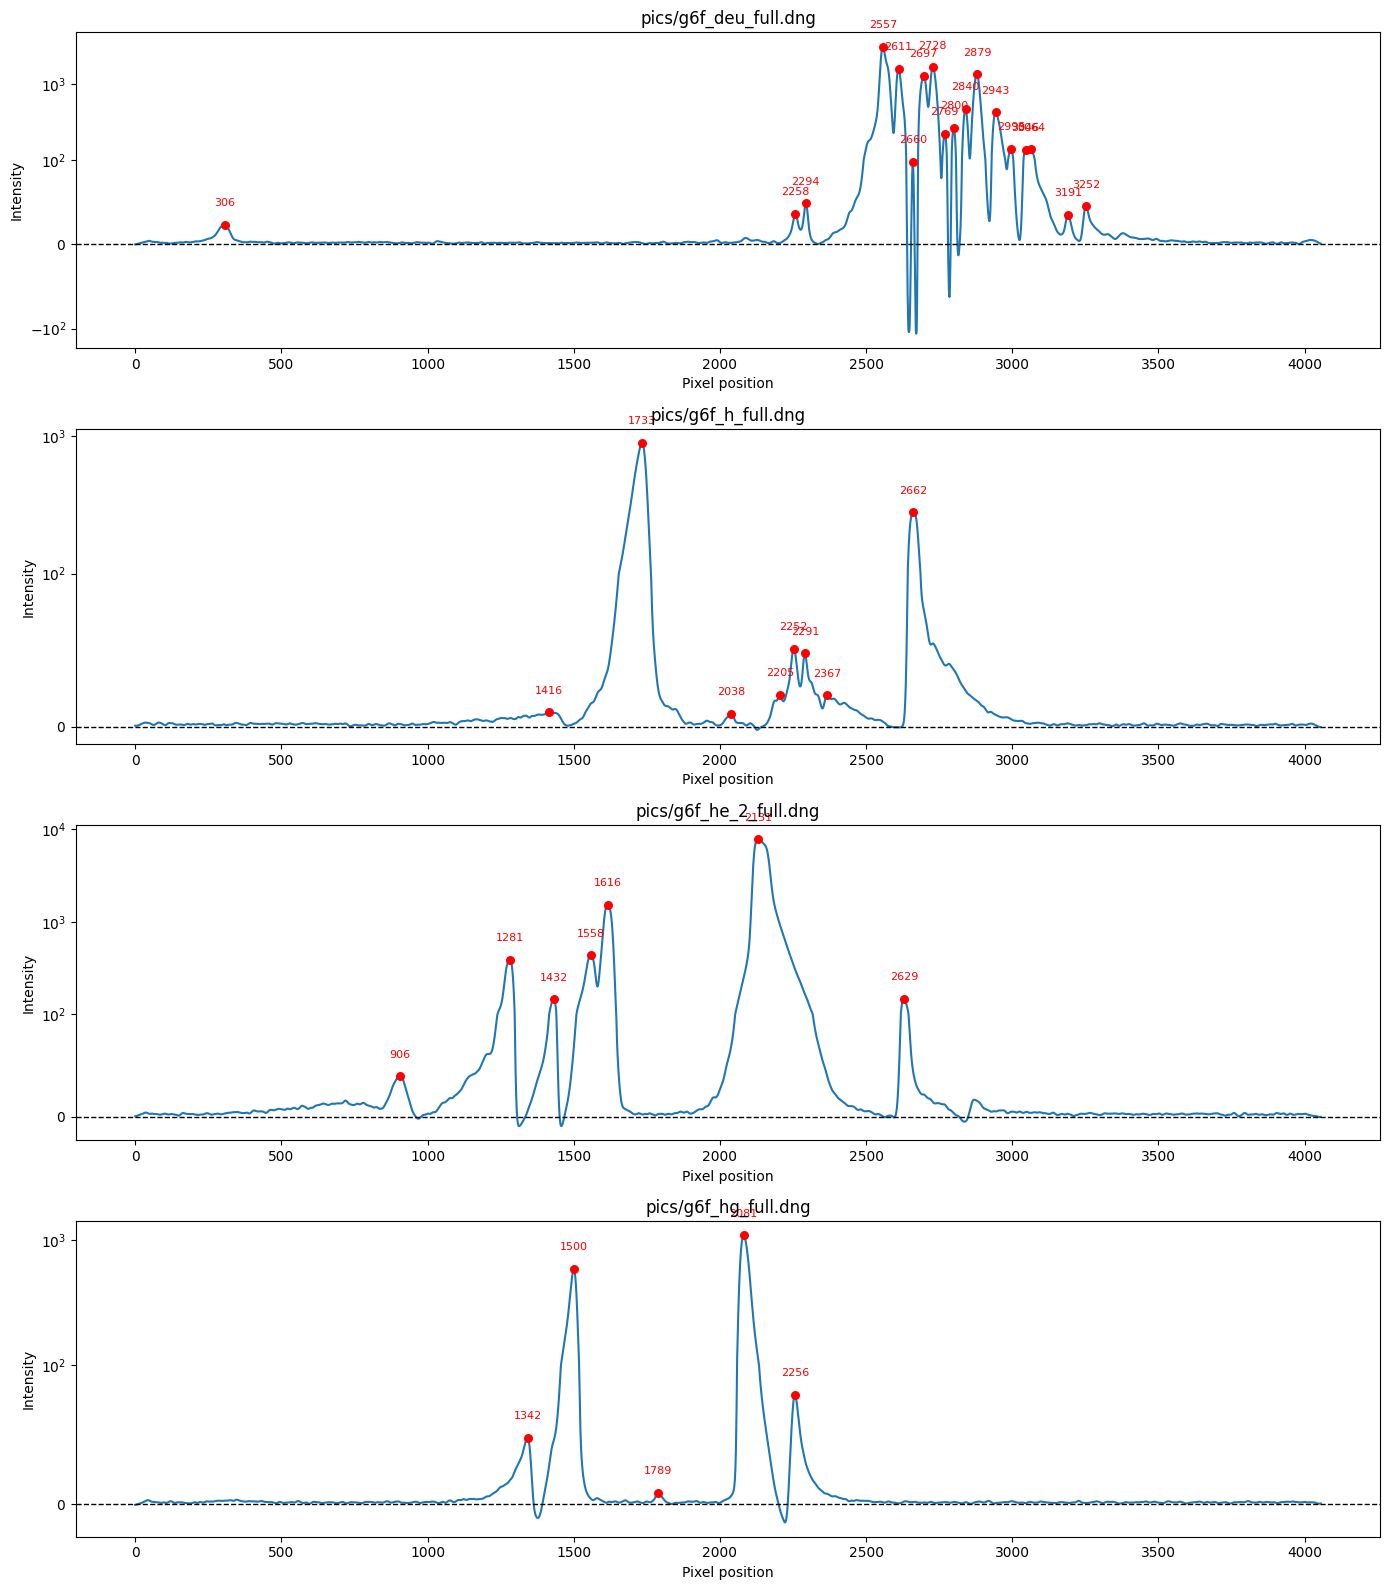

In [507]:
picFiles_list = sorted(glob.glob("pics/*.dng"))
total = len(picFiles_list)
# ok now actually do it

fig, axes = plt.subplots(total, 1, figsize=(14, 4 * total))

for ax, pic in zip(np.atleast_1d(axes).flat, picFiles_list):
    smoothed, peaks = find_peaks_corrected(pic)

    # Plot smoothed spectrum
    ax.plot(smoothed)

    # Red dots on detected peaks
    ax.scatter(
        peaks,
        smoothed[peaks],
        color="red",
        s=30,
        zorder=5
    )

    # Label each peak
    for x in peaks:
        ax.annotate(
            str(x),
            xy=(x, smoothed[x]),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            color="red"
        )

    ax.set_yscale("symlog", linthresh=100)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(pic)
    ax.set_xlabel("Pixel position")
    ax.set_ylabel("Intensity")

fig.tight_layout()
plt.show()

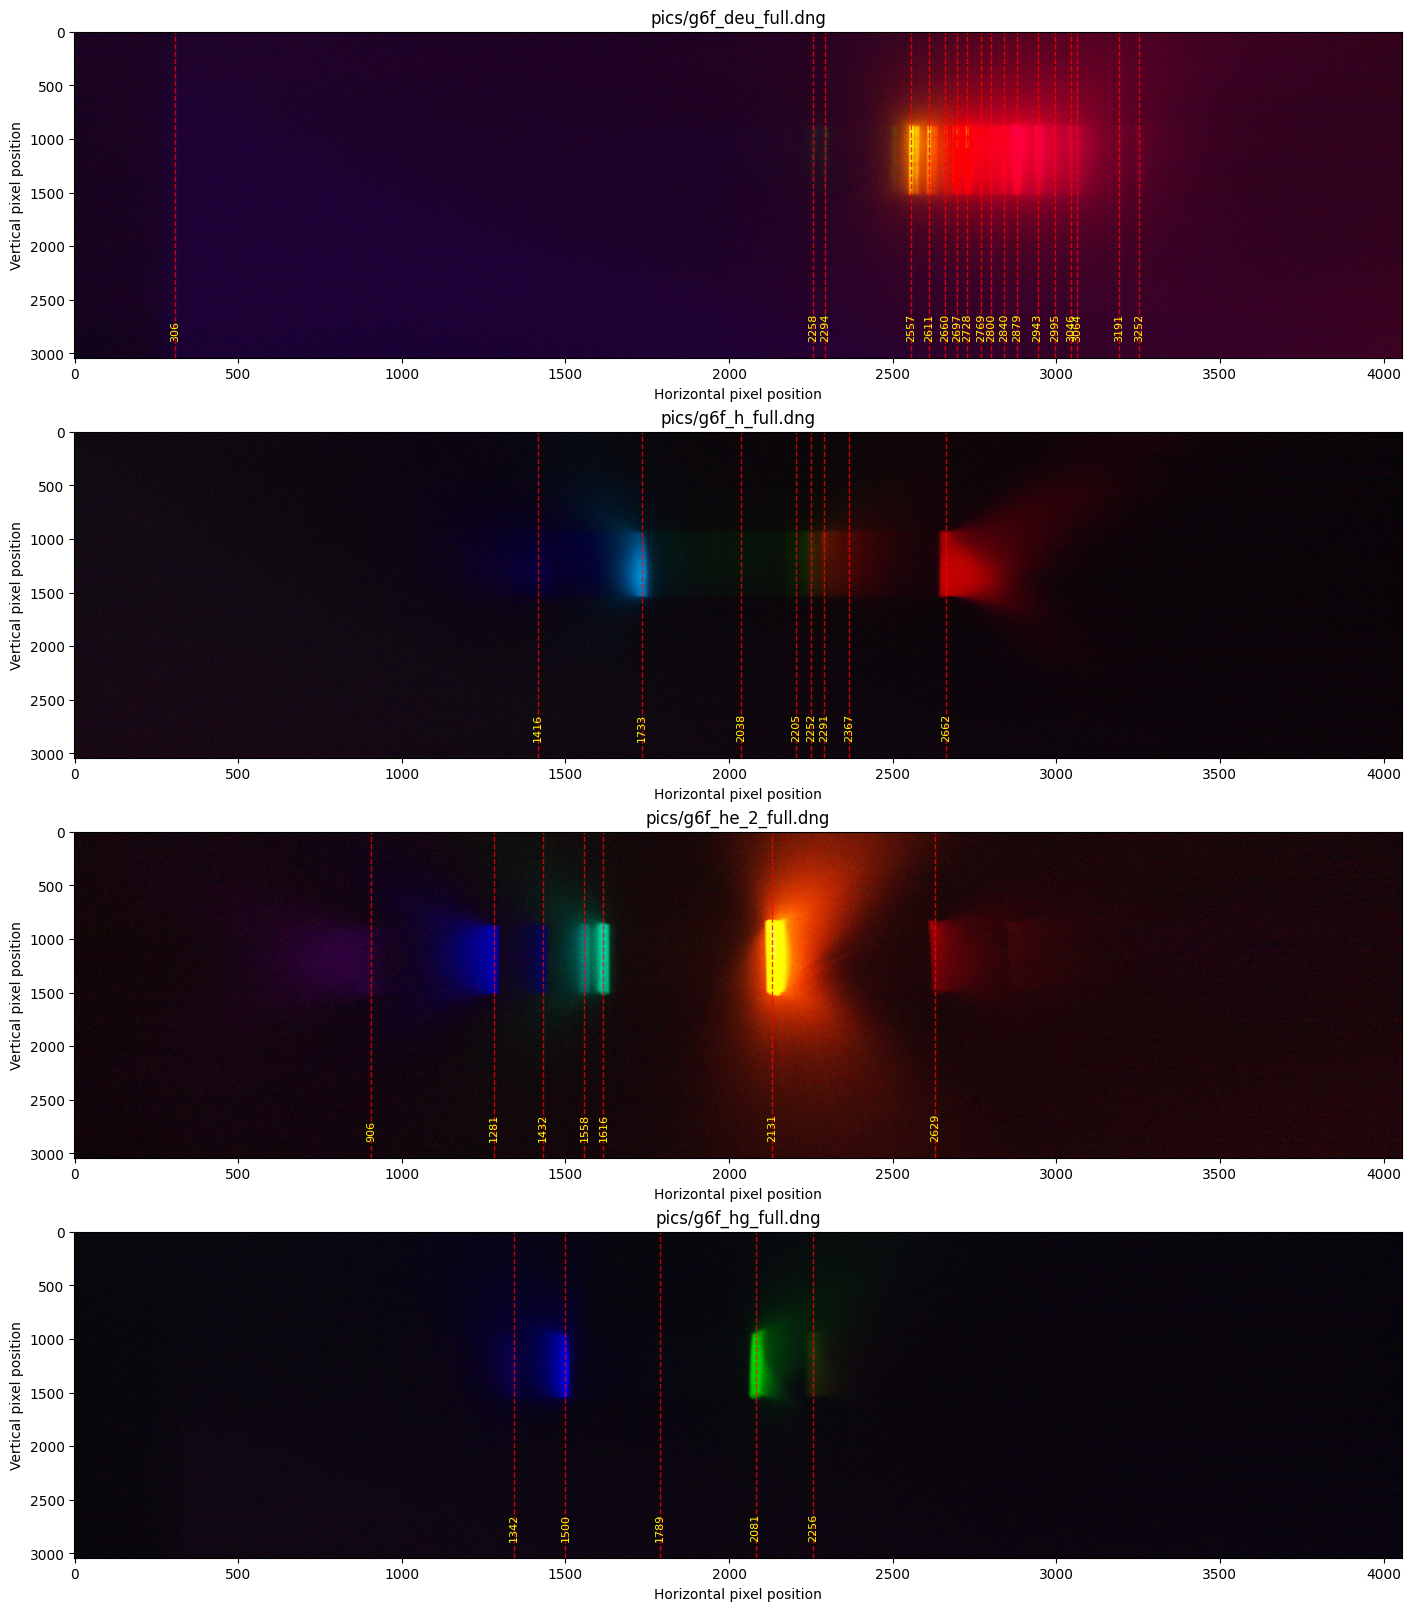

In [508]:
# heck yeah thats beautiful yayyy
# ok now to check if this lines up with img

total = len(picFiles_list)

fig, axes = plt.subplots(
    total, 1,
    figsize=(14, 4 * total),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, pic in zip(axes, picFiles_list):

    # read full-res RAW image
    with tifffile.TiffFile(pic) as tif:
        img = tif.series[1].asarray()

    # peaks
    smoothed, peaks = find_peaks_corrected(pic)

    # pic is the DNG path from picFiles_list
    jpg_path = Path("pics_jpgs") / (Path(pic).stem + ".jpg")

    if jpg_path.exists():
        # use colour JPEG if available
        img = np.asarray(Image.open(jpg_path).convert("RGB"))
    else:
        # fall back to grayscale RAW
        with tifffile.TiffFile(pic) as tif:
            img = tif.series[1].asarray()

    ax.imshow(img, cmap="gray" if img.ndim == 2 else None, aspect="auto")

    # vertical lines at detected peaks
    for x in peaks:
        ax.axvline(
            x,
            color="red",
            linestyle="--",
            linewidth=1,
            alpha=0.8
        )

        ax.text(
            x, 0.05,
            str(x),
            transform=ax.get_xaxis_transform(),
            color="yellow",
            fontsize=8,
            rotation=90,
            ha="center",
            va="bottom"
        )
    #ax.imshow(img)
    ax.set_title(pic)
    ax.set_xlabel("Horizontal pixel position")
    ax.set_ylabel("Vertical pixel position")

plt.show()


In [509]:
# test if it correctly removes baseline and not the actual peaks
def test_percentile_baseline_removal(pic):
    x, profiles, baseline = get_percentile_baseline(
        pic
    )

    fig, axes = plt.subplots(3, 1, figsize=(14, 9),
                            constrained_layout=True)

    for i, colour in enumerate(["red", "green", "blue"]):
        axes[i].plot(
            x, profiles[:, i],
            color=colour,
            label="RAW profile"
        )

        axes[i].plot(
            x, baseline[:, i],
            "k--",
            label="Estimated background"
        )   

        axes[i].set_title(colour.upper())
        axes[i].set_xlabel("Original pixel position")
        axes[i].set_ylabel("Mean RAW response")
        axes[i].legend()
        axes[i].grid(alpha=0.3)
    plt.suptitle(pic)
    plt.show()

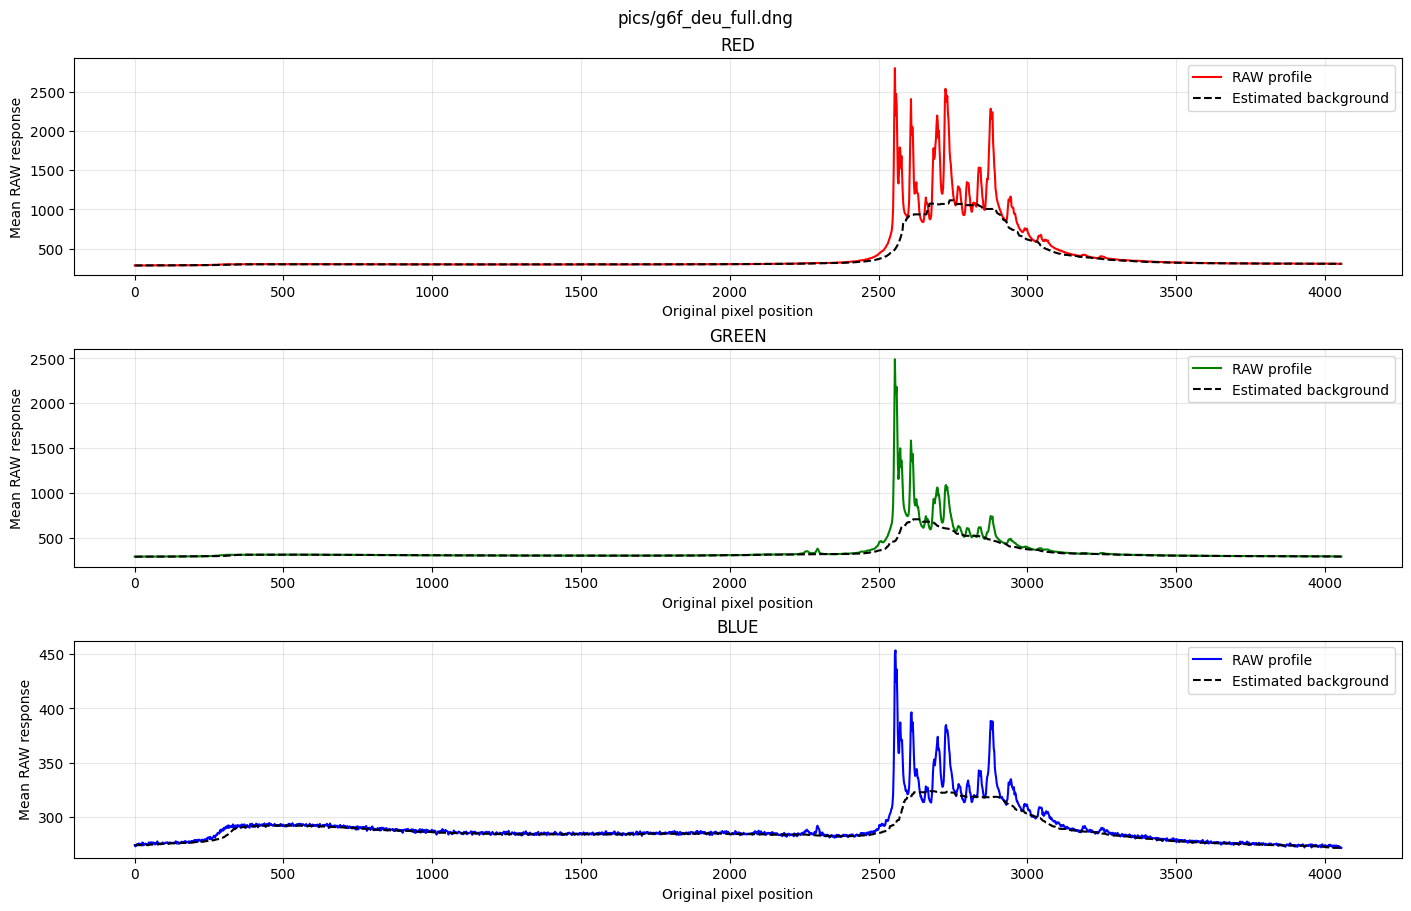

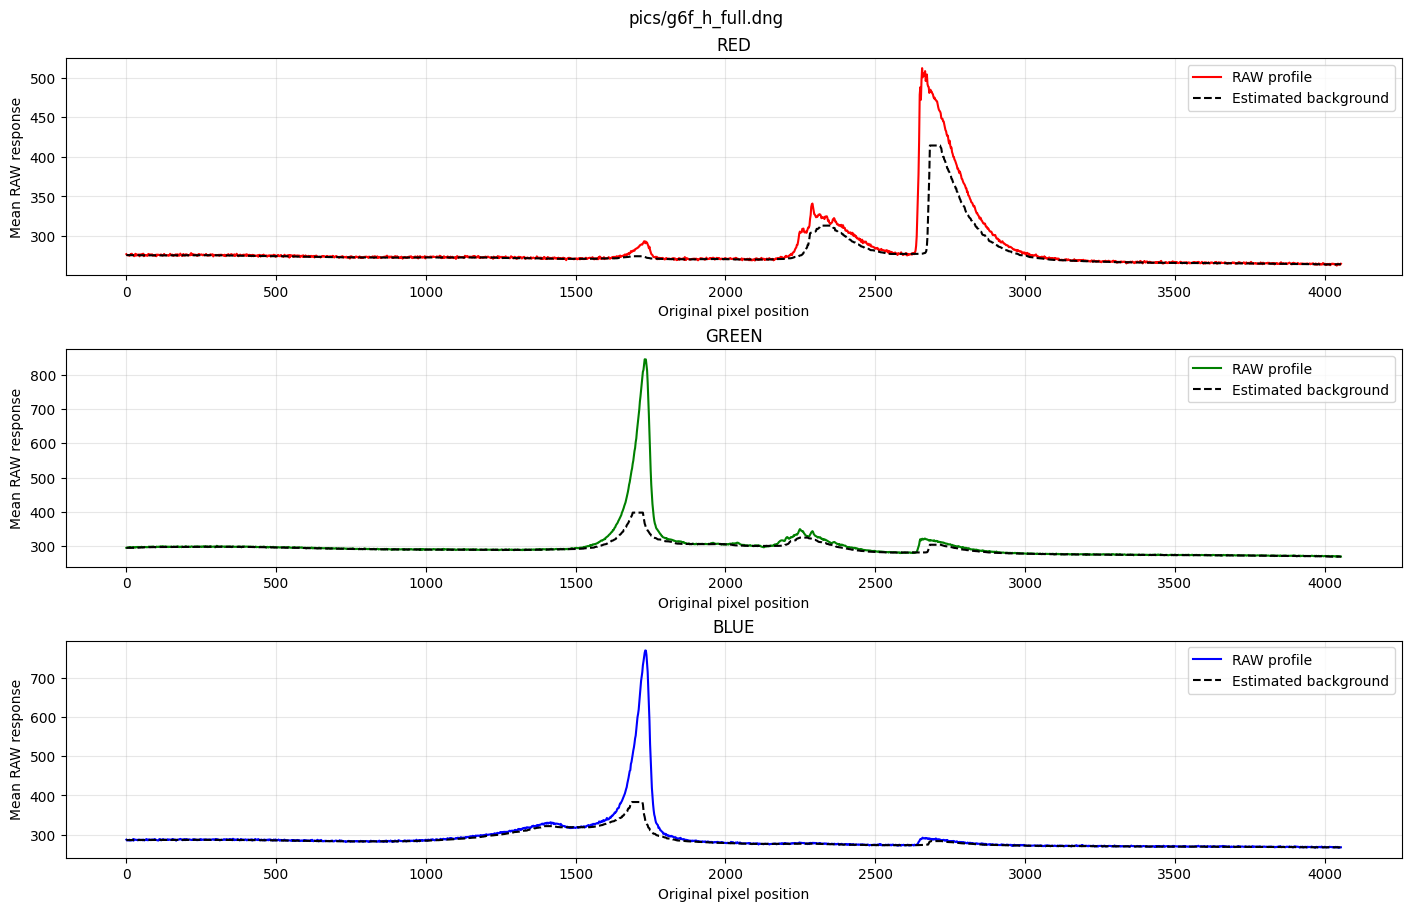

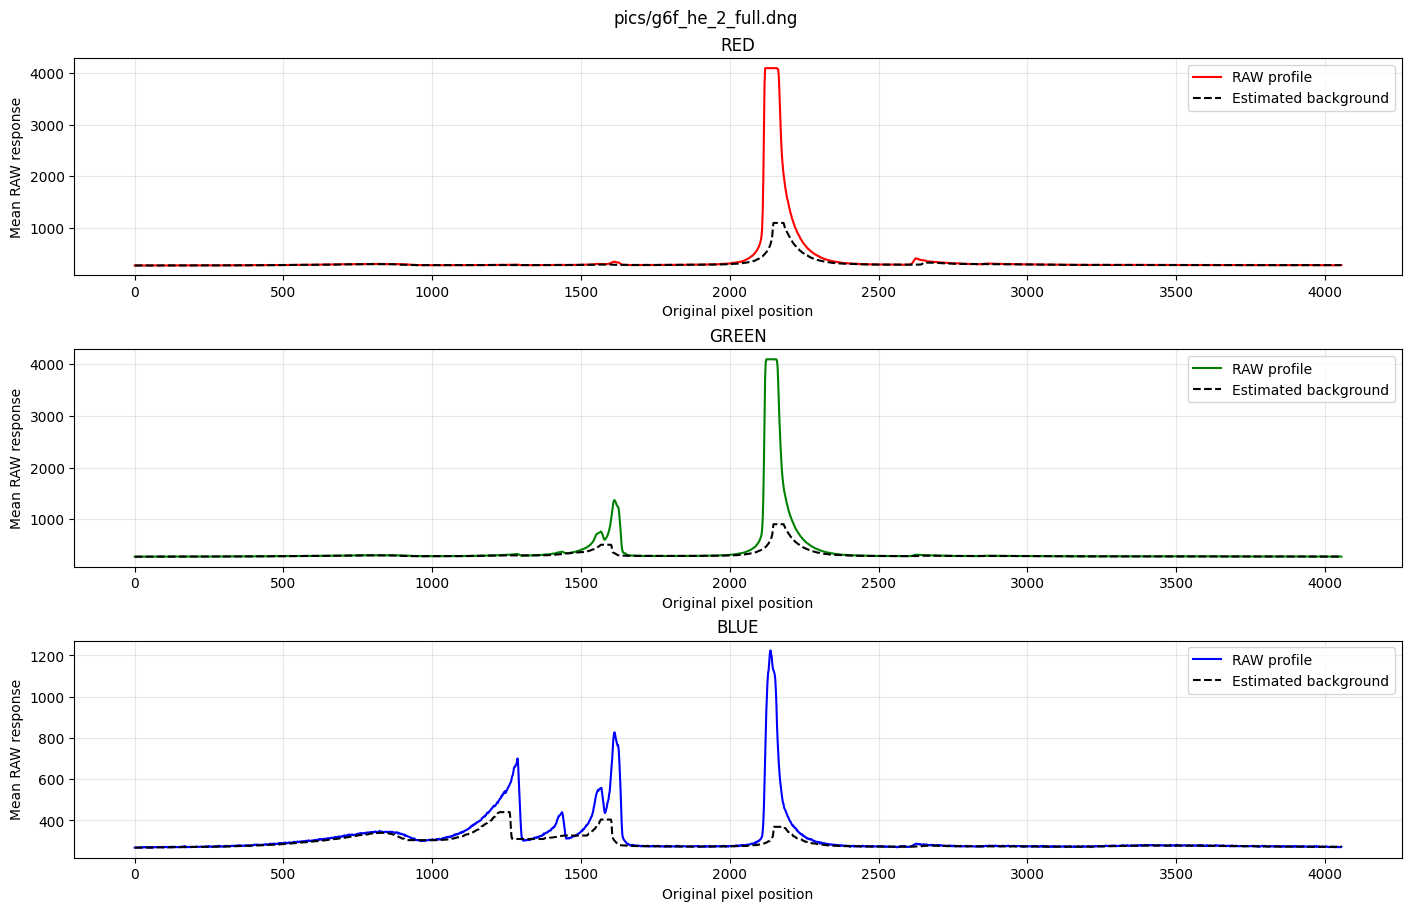

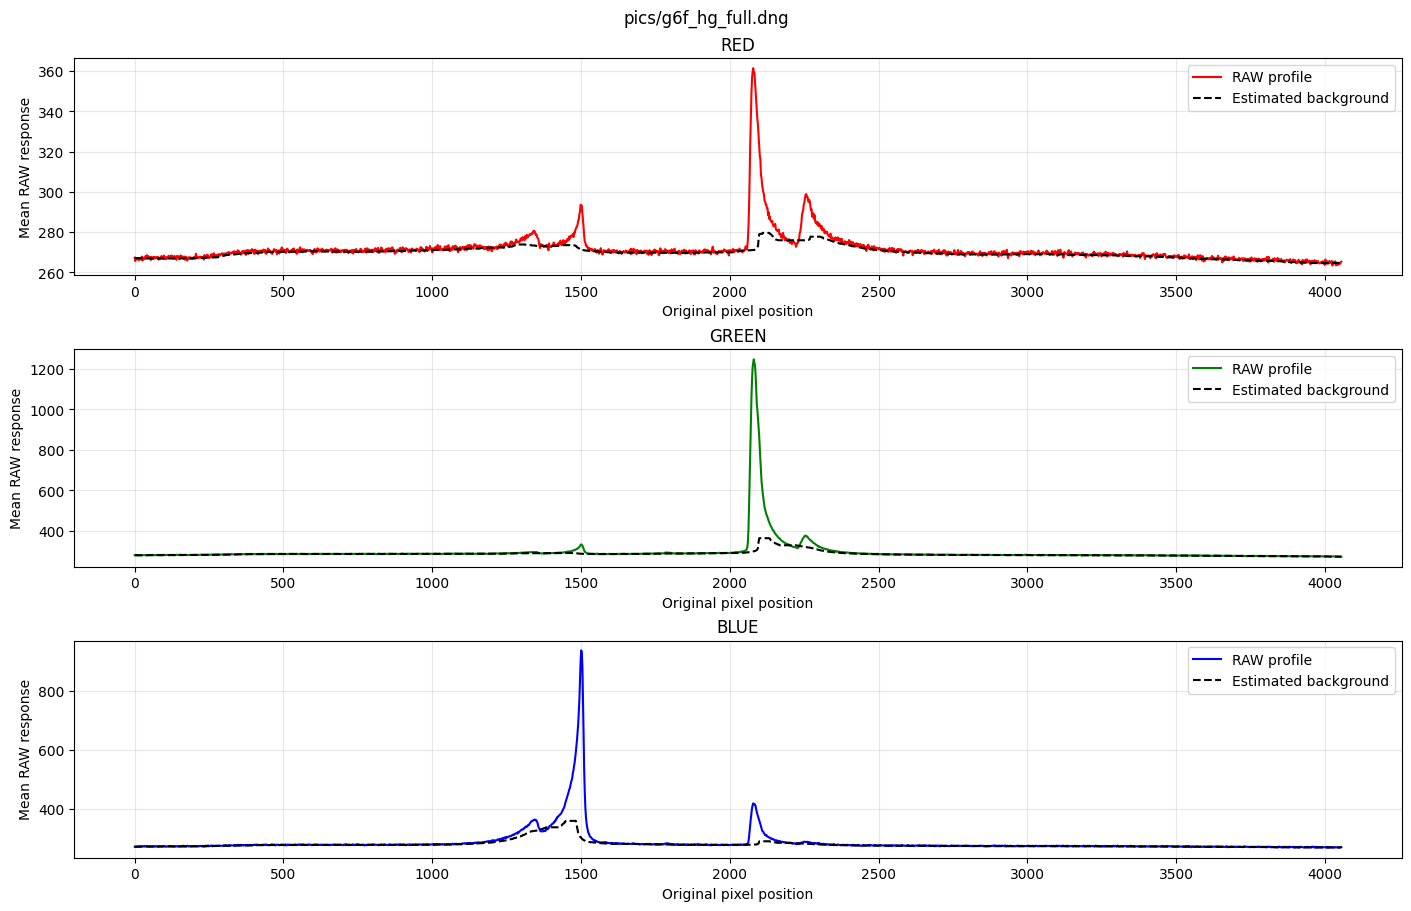

In [510]:
for pic in picFiles_list:
    test_percentile_baseline_removal(pic)

In [511]:
# Digitized IMX477 response curve
sensor = pd.read_csv("imx477_response.csv")
sensor = sensor.sort_values("wavelength_nm")

wl = sensor["wavelength_nm"].to_numpy()
responses = sensor[["R", "G", "B"]].to_numpy()

# Interpolate each sensor response
curves = [
    PchipInterpolator(wl, responses[:, i])
    for i in range(3)
]

wl_grid = np.linspace(400, 700, 3000) # visible light

rgb_grid = np.column_stack([
    curve(wl_grid) for curve in curves
])

# Normalize predicted sensor response
rgb_grid = np.clip(rgb_grid, 0, None)
rgb_grid /= rgb_grid.sum(axis=1, keepdims=True)

def predict_sensor_wavelength(data):
    measured = data[["r", "g", "b"]].to_numpy()

    distances = np.linalg.norm(
        measured[:, None, :] - rgb_grid[None, :, :],
        axis=2
    )

    nearest = distances.argmin(axis=1)

    return wl_grid[nearest], distances[
        np.arange(len(nearest)), nearest
    ]


In [512]:
# predictions

from scipy.optimize import linear_sum_assignment

def match_reference_peaks(data, references, tolerance=20):
    df = data.copy()
    df["actual_nm"] = np.nan
    df["reference_pixel"] = np.nan

    if df.empty or not references:
        return df

    detected = df["pixel"].to_numpy(dtype=float)
    ref_pixels = np.array(list(references), dtype=float)

    distances = np.abs(
        detected[:, None] - ref_pixels[None, :]
    )

    # Find one-to-one matches
    cost = distances.copy()
    cost[distances > tolerance] = 1e9

    rows, cols = linear_sum_assignment(cost)

    for i, j in zip(rows, cols):
        if distances[i, j] <= tolerance:
            idx = df.index[i]
            df.loc[idx, "actual_nm"] = references[int(ref_pixels[j])]
            df.loc[idx, "reference_pixel"] = ref_pixels[j]

    return df

# manual check and update
# ------- helium --------
print("helium predictions")
helium_bands = { # pixel pos : real wavelength
    905: 388.8,
    1282: 447.1,
    1432: 471.3,
    1557: 492.1,
    1616: 501.5,
    2129: 587.5,
    2628: 667.8
}

he = get_rgb_nobackground("pics/g6f_he_2_full.dng")
he = he[he["valid"]].copy()

he["estimated_nm"], he["colour_distance"] = (
    predict_sensor_wavelength(he)
)

display(he[
    ["pixel", "estimated_nm", "colour_distance"]
].round(2))

# ------- hydrogen -------
# pixel pos:legit
hydrogen_lines = {
    1416: 434,
    1734: 486,
    2660: 656 
}

print("hydrogen predictions")
h = get_rgb_nobackground("pics/g6f_h_full.dng")
h = h[h["valid"]].copy()

h["estimated_nm"], h["colour_distance"] = (
    predict_sensor_wavelength(h)
)

display(h[
    ["pixel", "estimated_nm", "colour_distance"]
].round(2))

# ------- mercury --------
mercury_lines = {
    1342: 404.7,
    1500: 435.8,
    2081: 546.1,
    2256: 576.9 # there's another at 579 which we can't resolve
}
print("mercury predicitons")
hg = get_rgb_nobackground("pics/g6f_hg_full.dng")
hg = hg[hg["valid"]].copy()

hg["estimated_nm"], hg["colour_distance"] = (
    predict_sensor_wavelength(hg)
)

display(hg[
    ["pixel", "estimated_nm", "colour_distance"]
].round(2))



helium predictions


,pixel,estimated_nm,colour_distance
0,906,400.00,0.22
1,1281,448.02,0.01
2,1432,472.92,0.00
3,1558,499.83,0.01
4,1616,506.24,0.01
5,2131,590.66,0.06
6,2629,665.39,0.01


hydrogen predictions


,pixel,estimated_nm,colour_distance
0,1416,421.41,0.02
1,1733,491.23,0.01
2,2038,524.94,0.03
3,2205,567.46,0.03
4,2252,595.17,0.01
5,2291,599.77,0.00
6,2367,591.06,0.00
7,2662,654.18,0.04


mercury predicitons


,pixel,estimated_nm,colour_distance
0,1342,408.30,0.01
1,1500,438.71,0.00
2,1789,495.03,0.07
3,2081,542.95,0.00
4,2256,580.86,0.02


ACCURACY SUMMARY


,Element,Lines,MAE (nm),RMSE (nm),Max error (nm),Mean % error
0,Helium,6,3.431,4.114,7.733,0.661
1,Hydrogen,3,6.546,7.942,12.593,1.418
2,Mercury,4,3.407,3.431,3.960,0.706
3,OVERALL,13,4.142,5.098,12.593,0.849


INDIVIDUAL LINE ERRORS


,element,pixel,actual_nm,estimated_nm,error_nm,percent_error
0,Helium,1281,447.1,448.016,0.916,0.205
1,Helium,1432,471.3,472.924,1.624,0.345
2,Helium,1558,492.1,499.833,7.733,1.571
3,Helium,1616,501.5,506.235,4.735,0.944
4,Helium,2131,587.5,590.664,3.164,0.538
5,Helium,2629,667.8,665.388,-2.412,0.361
6,Hydrogen,1416,434.0,421.407,-12.593,2.902
7,Hydrogen,1733,486.0,491.230,5.230,1.076
8,Hydrogen,2662,656.0,654.185,-1.815,0.277
9,Mercury,1342,404.7,408.303,3.603,0.890


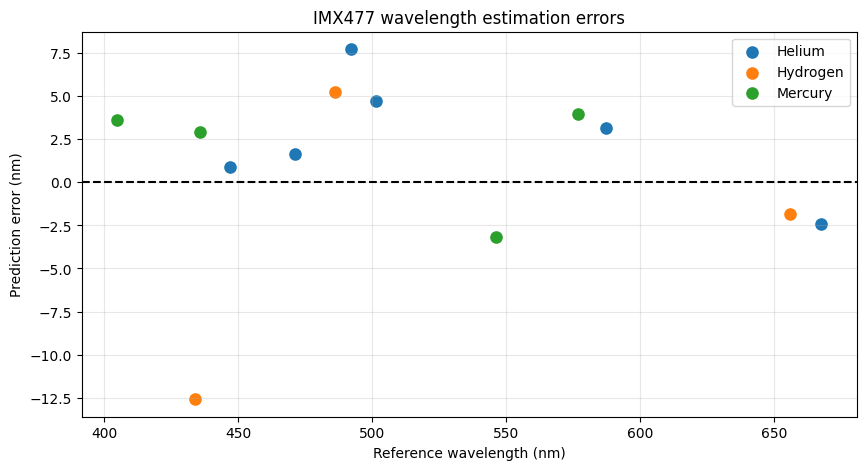

In [513]:
datasets = {
    "Helium": (he, helium_bands),
    "Hydrogen": (h, hydrogen_lines),
    "Mercury": (hg, mercury_lines)
}

results = []
summary = []

for element, (data, references) in datasets.items():

    # Exact matching against manually verified peak positions.
    df = data.copy()
    df = match_reference_peaks(df, references, tolerance=20)
    df = df.dropna(subset=["actual_nm", "estimated_nm"])

    # exclude wavelengths outside calibration range
    df = df[
        df["actual_nm"].between(wl_grid.min(), wl_grid.max())
    ].copy()

    # calculate errors
    df["error_nm"] = df["estimated_nm"] - df["actual_nm"]
    df["abs_error_nm"] = df["error_nm"].abs()
    df["percent_error"] = (
        100 * df["abs_error_nm"] / df["actual_nm"]
    )

    df["element"] = element
    results.append(df)

    if len(df) == 0:
        continue

    summary.append({
        "Element": element,
        "Lines": len(df),
        "MAE (nm)": df["abs_error_nm"].mean(),
        "RMSE (nm)": np.sqrt(np.mean(df["error_nm"]**2)),
        "Max error (nm)": df["abs_error_nm"].max(),
        "Mean % error": df["percent_error"].mean()
    })

# combine results
if not any(len(part) for part in results):
    raise ValueError("No manually assigned reference pixels matched detected peaks. Update the reference dictionaries in the predictions cell.")
all_results = pd.concat(results, ignore_index=True)

# overall statistics
summary.append({
    "Element": "OVERALL",
    "Lines": len(all_results),
    "MAE (nm)": all_results["abs_error_nm"].mean(),
    "RMSE (nm)": np.sqrt(np.mean(all_results["error_nm"]**2)),
    "Max error (nm)": all_results["abs_error_nm"].max(),
    "Mean % error": all_results["percent_error"].mean()
})

summary_df = pd.DataFrame(summary)

print("ACCURACY SUMMARY")
display(summary_df.round(3))

print("INDIVIDUAL LINE ERRORS")
display(all_results[
    ["element", "pixel", "actual_nm",
     "estimated_nm", "error_nm", "percent_error"]
].round(3))

# plot errors
fig, ax = plt.subplots(figsize=(10, 5))

for element, group in all_results.groupby("element"):
    ax.scatter(
        group["actual_nm"],
        group["error_nm"],
        s=65,
        label=element
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_xlabel("Reference wavelength (nm)")
ax.set_ylabel("Prediction error (nm)")
ax.set_title("IMX477 wavelength estimation errors")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


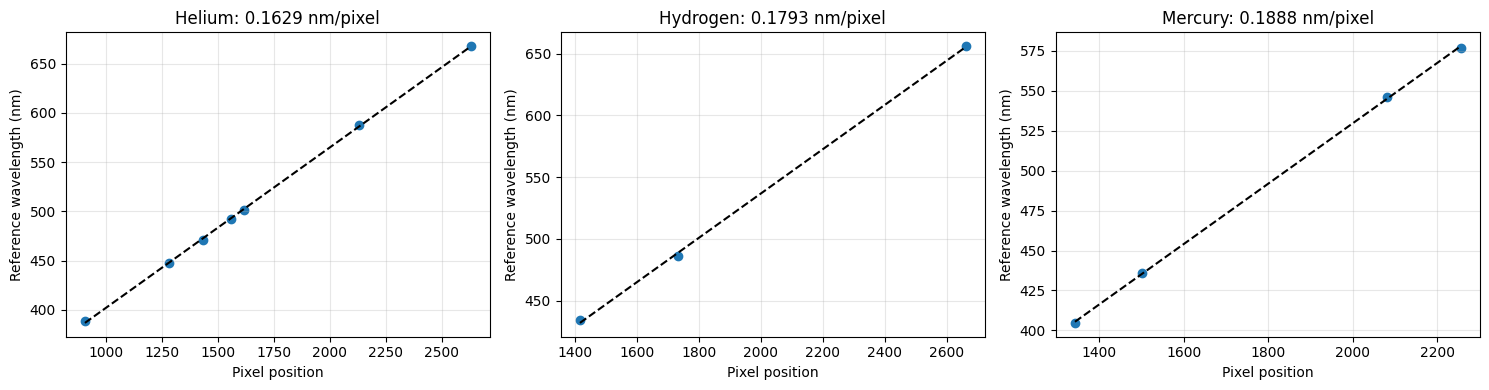

In [514]:
# getting better rectangle widths
datasets = {
    "Helium": (he, helium_bands),
    "Hydrogen": (h, hydrogen_lines),
    "Mercury": (hg, mercury_lines)
}

dispersion = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (element, (data, refs)) in zip(axes, datasets.items()):
    matched = data.copy()
    matched = match_reference_peaks(matched, refs, tolerance=20)
    matched = matched.dropna(subset=["actual_nm"])

    if len(matched) < 2:
        print(f"{element}: insufficient matched lines for dispersion")
        dispersion[element] = np.nan
        ax.set_title(f"{element}: insufficient matches")
        continue

    x = matched["pixel"].to_numpy()
    y = matched["actual_nm"].to_numpy()

    slope, intercept = np.polyfit(x, y, 1)

    dispersion[element] = abs(slope)

    ax.scatter(x, y)
    ax.plot(x, slope*x + intercept, "k--")

    ax.set_title(
        f"{element}: {abs(slope):.4f} nm/pixel"
    )
    ax.set_xlabel("Pixel position")
    ax.set_ylabel("Reference wavelength (nm)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

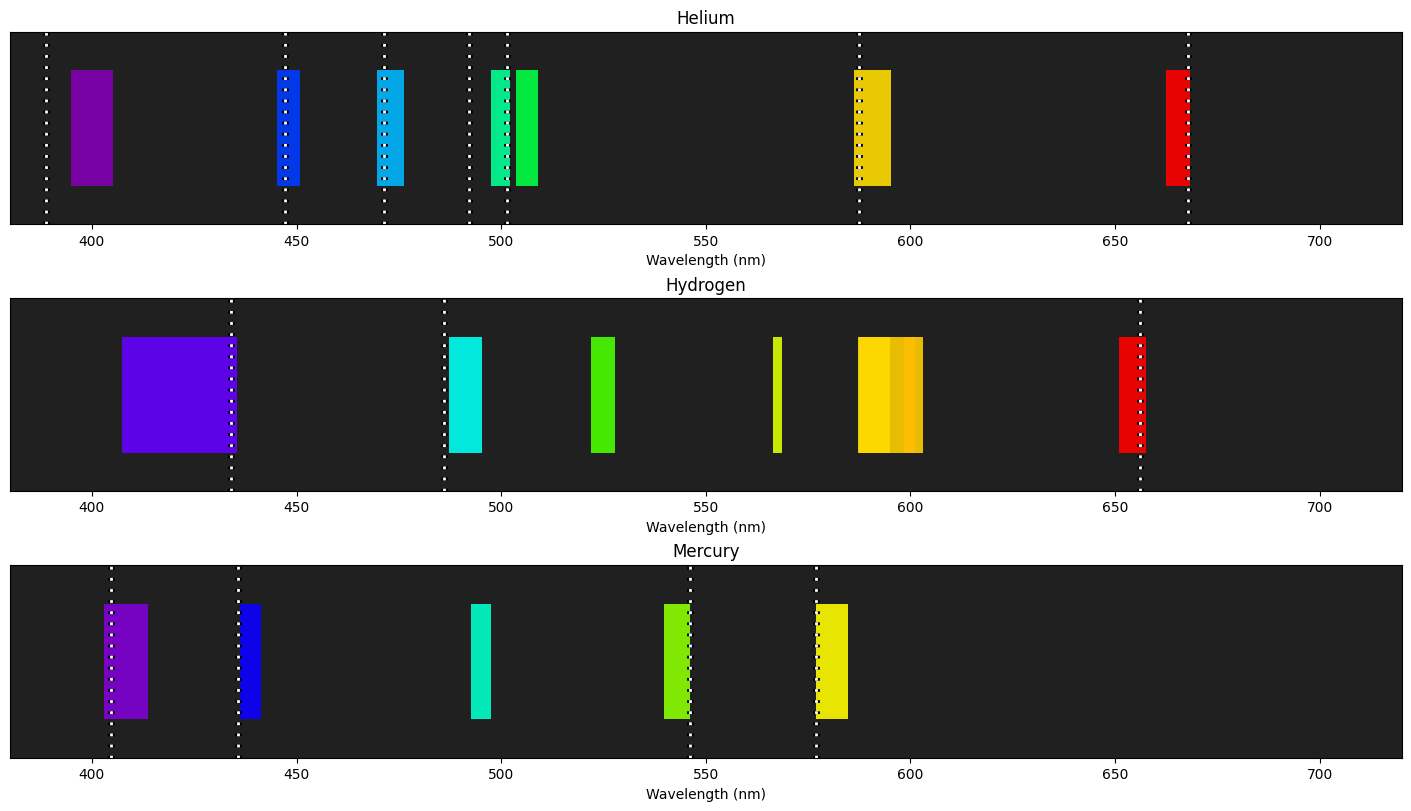

In [515]:
# colourssss

datasets = {
    "Helium": ("pics/g6f_he_2_full.dng", he, helium_bands),
    "Hydrogen": ("pics/g6f_h_full.dng", h, hydrogen_lines),
    "Mercury": ("pics/g6f_hg_full.dng", hg, mercury_lines)
}

# make wavelength colours matplotlib comparable
def wavelength_to_rgb(wavelength):
    """Approximate visible wavelength (nm) to display RGB."""

    w = float(wavelength)

    if not 380 <= w <= 780:
        return (0.0, 0.0, 0.0)

    if w < 440:
        r, g, b = -(w-440)/(440-380), 0, 1
    elif w < 490:
        r, g, b = 0, (w-440)/(490-440), 1
    elif w < 510:
        r, g, b = 0, 1, -(w-510)/(510-490)
    elif w < 580:
        r, g, b = (w-510)/(580-510), 1, 0
    elif w < 645:
        r, g, b = 1, -(w-645)/(645-580), 0
    else:
        r, g, b = 1, 0, 0

    # Reduce brightness near visible-spectrum boundaries
    if w < 420:
        factor = 0.3 + 0.7*(w-380)/(420-380)
    elif w > 700:
        factor = 0.3 + 0.7*(780-w)/(780-700)
    else:
        factor = 1.0

    gamma = 0.8

    return tuple(
        (max(0, c) * factor)**gamma
        for c in (r, g, b)
    )

# Approximate display conversion, not a calibrated linewidth
nm_per_pixel = 0.15

fig, axes = plt.subplots(
    3, 1, figsize=(14, 8),
    constrained_layout=True
)

for ax, (element, (pic, data, references)) in zip(
    axes, datasets.items()
):
    # Get peak widths from RAW intensity profile
    smoothed, peaks = find_peaks_corrected(pic)

    widths, _, _, _ = peak_widths(
        smoothed, peaks, rel_height=0.5
    )

    width_map = dict(zip(peaks.astype(int), widths))



    y0, y1 = get_band(pic)

    for _, row in data.iterrows():
        x = int(row["pixel"])
        wavelength = float(row["estimated_nm"])

        # Measured width in pixels -> approximate nm
        width_px = width_map.get(x, 10)
        width_nm = width_px * dispersion[element]
        if not np.isfinite(width_nm):
            continue

        # colour
        rgb = wavelength_to_rgb(wavelength)

        # Solid coloured measured band
        rect = Rectangle(
            (wavelength - width_nm/2, 0),
            width_nm,
            1,
            facecolor=rgb,
            edgecolor="none",
            alpha=0.9
        )

        ax.add_patch(rect)
        rect.set_y(0.2)
        rect.set_height(0.6)

    # theoretical reference lines as dotted vertical markers
    for actual_nm in references.values():
        line = ax.axvline(
            actual_nm,
            color="white",
            linestyle=(0, (1, 3)),
            linewidth=2,
            ymin=0,
            ymax=1
        )
        line.set_path_effects([
            pe.Stroke(linewidth=5, foreground="black"),
            pe.Normal()])


    ax.set_xlim(380, 720)
    ax.set_ylim(0, 1)
    ax.set_facecolor("#202020")
    ax.set_yticks([])
    ax.set_xlabel("Wavelength (nm)")
    ax.set_title(element)
    ax.grid(False)

plt.show()



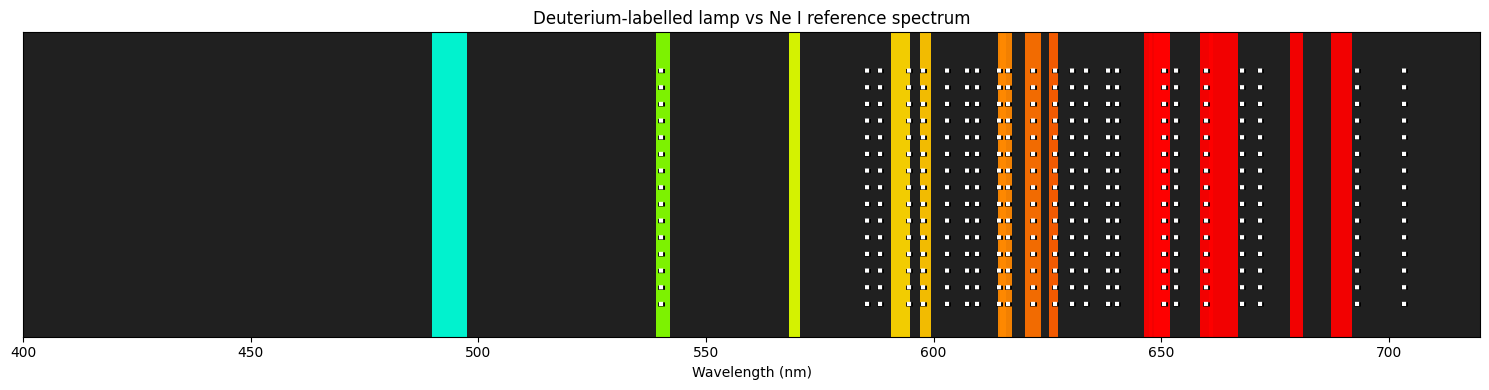

,pixel,estimated_nm,colour_distance
0,306,493.631,0.263
1,2258,569.356,0.024
2,2294,540.547,0.019
3,2557,592.764,0.005
4,2611,598.266,0.004
5,2660,647.082,0.063
6,2697,615.872,0.003
7,2728,621.874,0.004
8,2769,615.072,0.001
9,2800,626.375,0.004


In [516]:
# sus.

pic = "pics/g6f_deu_full.dng"

# Prominent Ne I reference wavelengths (nm)
neon_reference_nm = [
    540.06, 585.25, 588.19, 594.48, 597.55,
    603.00, 607.43, 609.62, 614.31, 616.36,
    621.73, 626.65, 630.48, 633.44, 638.30,
    640.22, 650.65, 653.29, 659.90, 667.83,
    671.70, 692.95, 703.24
]

# Extract measured RGB and predict wavelengths
deu = get_rgb_nobackground(pic)
deu = deu[deu["valid"]].copy()

deu["estimated_nm"], deu["colour_distance"] = (
    predict_sensor_wavelength(deu)
)

# Get peak widths from RAW profile
smoothed, peaks = find_peaks_corrected(pic)

widths, _, _, _ = peak_widths(
    smoothed, peaks, rel_height=0.5
)

width_map = dict(zip(peaks.astype(int), widths))

# Same approximate display-width conversion as before
nm_per_pixel = 0.15

fig, ax = plt.subplots(figsize=(15, 4))

# Measured bands
for _, row in deu.iterrows():
    x = int(row["pixel"])
    wavelength = float(row["estimated_nm"])

    width_px = width_map.get(x, 10)
    width_nm = max(1, width_px * nm_per_pixel)

    rgb = wavelength_to_rgb(wavelength)

    ax.add_patch(Rectangle(
        (wavelength - width_nm/2, 0),
        width_nm,
        1,
        facecolor=rgb,
        edgecolor="none",
        alpha=0.95,
        zorder=2
    ))

# Neon reference lines: white dots with black outline
for actual_nm in neon_reference_nm:
    line = ax.axvline(
        actual_nm,
        color="white",
        linestyle=(0, (1, 3)),
        linewidth=3,
        ymin=0.1,
        ymax=0.9,
        zorder=10
    )

    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground="black"),
        pe.Normal()
    ])

ax.set_xlim(400, 720)
ax.set_ylim(0, 1)
ax.set_facecolor("#202020")
ax.set_yticks([])
ax.set_xlabel("Wavelength (nm)")
ax.set_title("Deuterium-labelled lamp vs Ne I reference spectrum")
ax.grid(False)

plt.tight_layout()
plt.show()

display(
    deu[["pixel", "estimated_nm", "colour_distance"]]
    .round(3)
)


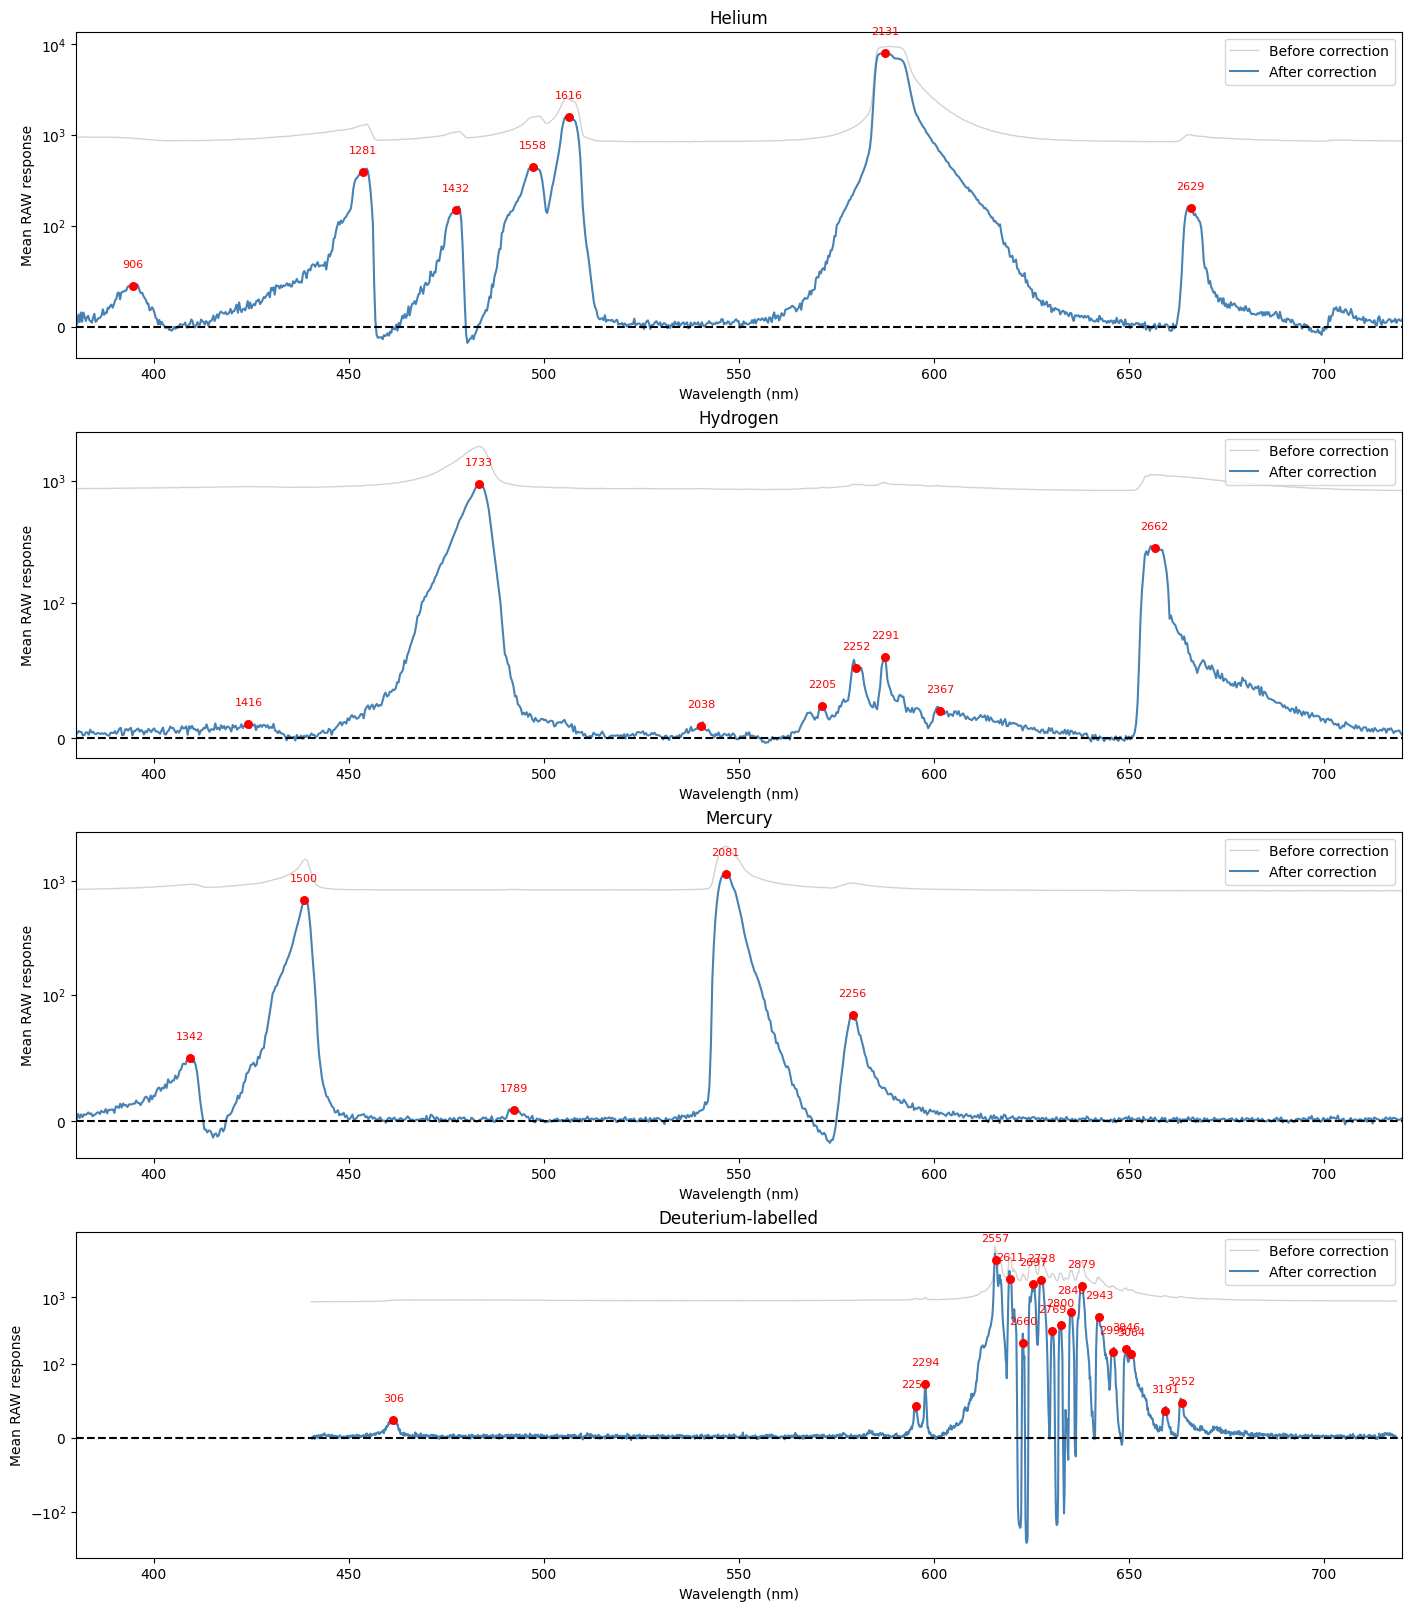

In [517]:
datasets = {
    "Helium": (
        "pics/g6f_he_2_full.dng",
        he,
        [388.8, 447.1, 471.3, 492.1, 501.5, 587.5, 667.8, 706.5]
    ),
    "Hydrogen": (
        "pics/g6f_h_full.dng",
        h,
        [410.17, 434.05, 486.13, 656.28]
    ),
    "Mercury": (
        "pics/g6f_hg_full.dng",
        hg,
        [404.66, 435.83, 546.07, 576.96, 579.07]
    ),
    "Deuterium-labelled": (
        "pics/g6f_deu_full.dng",
        deu,
        neon_reference_nm
    )
}

fig, axes = plt.subplots(
    len(datasets), 1,
    figsize=(14, 4 * len(datasets)),
    constrained_layout=True
)

for ax, (element, (pic, data, refs)) in zip(
    np.atleast_1d(axes).flat, datasets.items()
):

    # Original peak positions (full-resolution pixels)
    smoothed, peaks = find_peaks_corrected(pic)

    # Get Bayer RGB profiles and percentile background
    x, profiles, baseline = get_percentile_baseline(
        pic
    )

    # Corrected intensity (do not clip negative values)
    corrected = profiles - baseline

    raw_intensity = profiles.sum(axis=1)
    corrected_intensity = corrected.sum(axis=1)

    # Fit pixel -> wavelength using RGB-estimated peaks
    valid = data.dropna(
        subset=["pixel", "estimated_nm"]
    ).sort_values("pixel")

    x_cal = valid["pixel"].to_numpy()
    wl_cal = valid["estimated_nm"].to_numpy()

    if len(x_cal) < 2:
        ax.set_title(f"{element}: insufficient valid RGB estimates")
        continue
    slope, intercept = np.polyfit(x_cal, wl_cal, 1)

    # Convert Bayer-profile positions into wavelength
    wavelength_axis = slope * x + intercept

    # Interpolate corrected intensity at detected peak positions
    peak_intensity = np.interp(
        peaks, x, corrected_intensity
    )

    peak_wavelengths = slope * peaks + intercept

    # Uncorrected spectrum (faint grey)
    ax.plot(
        wavelength_axis,
        raw_intensity,
        color="grey",
        alpha=0.35,
        linewidth=1,
        label="Before correction"
    )

    # Corrected spectrum
    ax.plot(
        wavelength_axis,
        corrected_intensity,
        color="steelblue",
        linewidth=1.5,
        label="After correction"
    )

    # Detected peaks
    ax.scatter(
        peak_wavelengths,
        peak_intensity,
        color="red",
        s=30,
        zorder=5
    )

    # Label original pixel positions
    for px, wl, intensity in zip(
        peaks, peak_wavelengths, peak_intensity
    ):
        ax.annotate(
            str(int(px)),
            xy=(wl, intensity),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            color="red"
        )

    # Theoretical emission lines
    # Actually we can't do this any more as the official calibration curve isn't
    # linear
    # so the theoretical lines will always be off on this plot
    # for ref in refs:
    #     ax.axvline(
    #         ref,
    #         color="black",
    #         linestyle=":",
    #         linewidth=1.5,
    #         alpha=0.7,
    #         zorder=3
    #     )

    # Symmetric logarithmic scale includes zero
    ax.set_yscale("symlog", linthresh=100)

    # Zero baseline
    ax.axhline(
        y=0,
        color="black",
        linestyle="--",
        linewidth=1.5,
        zorder=10
    )

    ax.set_xlim(380, 720)
    ax.set_title(element)
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel("Mean RAW response")
    ax.grid(False)
    ax.legend(loc="upper right")

plt.show()


In [518]:

datasets = {
    "Helium": ("pics/g6f_he_2_full.dng", helium_bands),
    "Hydrogen": ("pics/g6f_h_full.dng", hydrogen_lines),
    "Mercury": ("pics/g6f_hg_full.dng", mercury_lines)
}

records = []

for element, (pic, refs) in datasets.items():

    methods = {
        "Local background": get_rgb_nobackground(pic),
        "Percentile baseline": get_rgb_percentile(pic)
    }

    for method, data in methods.items():
        valid = data[data["valid"]].copy()

        if valid.empty:
            continue

        valid["estimated_nm"], valid["colour_distance"] = (
            predict_sensor_wavelength(valid)
        )

        valid["actual_nm"] = valid["pixel"].map(refs)

        valid = valid.dropna(subset=["actual_nm"])
        valid = valid[
            valid["actual_nm"].between(
                wl_grid.min(), wl_grid.max()
            )
        ]

        for _, row in valid.iterrows():
            records.append({
                "element": element,
                "pixel": int(row["pixel"]),
                "method": method,
                "actual_nm": row["actual_nm"],
                "estimated_nm": row["estimated_nm"],
                "error_nm": row["estimated_nm"] - row["actual_nm"],
                "colour_distance": row["colour_distance"]
            })

comparison = pd.DataFrame(records)

# Only compare lines valid under both methods
counts = comparison.groupby(
    ["element", "pixel"]
)["method"].nunique()

common = counts[counts == 2].index

fair = comparison.set_index(
    ["element", "pixel"]
).loc[common].reset_index()

summary = fair.groupby(
    ["element", "method"]
).agg(
    lines=("pixel", "count"),
    MAE_nm=("error_nm", lambda x: np.mean(np.abs(x))),
    RMSE_nm=("error_nm", lambda x: np.sqrt(np.mean(x**2)))
).reset_index()

display(summary.round(3))


,element,method,lines,MAE_nm,RMSE_nm
0,Helium,Local background,2,3.180,3.540
1,Helium,Percentile baseline,2,3.180,3.540
2,Hydrogen,Local background,1,12.593,12.593
3,Hydrogen,Percentile baseline,1,12.593,12.593
4,Mercury,Local background,4,3.407,3.431
5,Mercury,Percentile baseline,4,3.407,3.431


Expected reference lines: 13

BEST COMPLETE CONFIGURATIONS


,percentile,window,lines,MAE_nm,RMSE_nm,max_error_nm
48,35,71,13,3.185,3.537,6.333
49,35,81,13,3.215,3.727,7.833
56,40,61,13,3.369,3.656,6.004
39,30,71,13,3.381,3.885,7.233
50,35,101,13,3.490,4.037,8.634
38,30,61,13,3.500,3.876,6.533
29,25,61,13,3.550,4.187,8.191
40,30,81,13,3.558,3.989,7.833
47,35,61,13,3.623,3.869,5.531
51,35,121,13,3.775,4.405,9.334



ALL CONFIGURATIONS


,percentile,window,lines,MAE_nm,RMSE_nm,max_error_nm
48,35,71,13,3.185,3.537,6.333
49,35,81,13,3.215,3.727,7.833
56,40,61,13,3.369,3.656,6.004
39,30,71,13,3.381,3.885,7.233
19,20,51,12,3.468,3.979,7.133
...,...,...,...,...,...,...
7,10,151,13,6.017,7.812,18.508
52,35,151,13,6.360,9.244,27.821
33,25,121,13,6.645,10.428,32.522
43,30,151,13,7.014,10.444,31.822


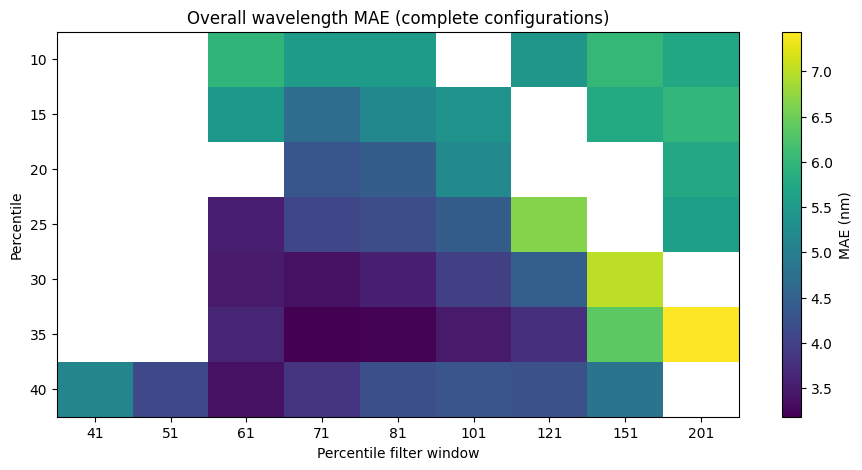

Best tested setting: percentile=35, window=71, MAE=3.185 nm


In [519]:
# Parameters to test
percentiles = [10, 15, 20, 25, 30, 35, 40]
windows = [41, 51, 61, 71, 81, 101, 121, 151, 201]

# Manually verified reference positions
datasets = {
    "Helium": ("pics/g6f_he_2_full.dng", helium_bands),
    "Hydrogen": ("pics/g6f_h_full.dng", hydrogen_lines),
    "Mercury": ("pics/g6f_hg_full.dng", mercury_lines)
}

records = []

for percentile in percentiles:
    for window in windows:
        for element, (pic, refs) in datasets.items():

            data = get_rgb_percentile(
                pic,
                percentile=percentile,
                window=window
            )

            data = data[data["valid"]].copy()

            if data.empty:
                continue

            data["estimated_nm"], _ = (
                predict_sensor_wavelength(data)
            )

            # Flexible matching as peaks move
            data = match_reference_peaks(
                data, refs, tolerance=20
            )

            data = data.dropna(subset=["actual_nm"])
            data = data[
                data["actual_nm"].between(
                    wl_grid.min(), wl_grid.max()
                )
            ]

            for _, row in data.iterrows():
                records.append({
                    "percentile": percentile,
                    "window": window,
                    "element": element,
                    "pixel": int(row["pixel"]),
                    "reference_pixel": row["reference_pixel"],
                    "actual_nm": row["actual_nm"],
                    "estimated_nm": row["estimated_nm"],
                    "error_nm": row["estimated_nm"] - row["actual_nm"]
                })

sweep = pd.DataFrame(records)

# Calculate accuracy for each configuration
summary = sweep.groupby(
    ["percentile", "window"]
).agg(
    lines=("error_nm", "count"),
    MAE_nm=("error_nm", lambda x: np.mean(np.abs(x))),
    RMSE_nm=("error_nm", lambda x: np.sqrt(np.mean(x**2))),
    max_error_nm=("error_nm", lambda x: np.max(np.abs(x)))
).reset_index()

# Only compare settings that recover all expected in-range lines
expected_lines = sum(
    sum(wl_grid.min() <= wl <= wl_grid.max()
        for wl in refs.values())
    for _, refs in datasets.values()
)

complete = summary[
    summary["lines"] == expected_lines
].sort_values("MAE_nm")

print(f"Expected reference lines: {expected_lines}")

print("\nBEST COMPLETE CONFIGURATIONS")
display(complete.head(15).round(3))

print("\nALL CONFIGURATIONS")
display(summary.sort_values("MAE_nm").round(3))

# Plot MAE heatmap for complete configurations
if not complete.empty:
    heatmap = complete.pivot(
        index="percentile",
        columns="window",
        values="MAE_nm"
    )

    fig, ax = plt.subplots(figsize=(11, 5))
    image = ax.imshow(heatmap, aspect="auto", cmap="viridis")

    ax.set_xticks(range(len(heatmap.columns)))
    ax.set_xticklabels(heatmap.columns)
    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)

    ax.set_xlabel("Percentile filter window")
    ax.set_ylabel("Percentile")
    ax.set_title("Overall wavelength MAE (complete configurations)")

    fig.colorbar(image, ax=ax, label="MAE (nm)")
    plt.show()

    best = complete.iloc[0]
    print(
        f"Best tested setting: "
        f"percentile={int(best['percentile'])}, "
        f"window={int(best['window'])}, "
        f"MAE={best['MAE_nm']:.3f} nm"
    )
else:
    print("No configuration recovered all expected lines.")
